# 00 · Capa batch: ETL del histórico TRCU.csv

**Proyecto:** NIDS campus · tráfico de red de un laboratorio de la UPeU
**Equipo:** Nick Saim Mayta Jara · David Romero Nina · Henyelrey Lucio Garcia Chura · Jhan Logan Ramos Quispe

Este notebook es la **capa batch** de la arquitectura Lambda del proyecto. Toma el
histórico de flujos capturado en la universidad (1-jul a 1-sep-2026, formato
NTLFlowLyzer / CICFlowMeter) y lo deja listo para análisis y modelos:

1. Lectura y perfil del dato crudo
2. Validación de calidad (nulos, duplicados, rangos, etiquetas)
3. Limpieza, tipado y seudonimización de IP (Ley 29733)
4. Escritura en Parquet particionado por fecha (Silver) y agregado por minuto (Gold)
5. Evidencia de *partition pruning*

La agregación por minuto usa **la misma función** (`agregar_por_minuto` de
`nube/spark/jobs/comun.py`) que el job de streaming: capa batch y capa de
velocidad calculan los indicadores de una sola forma.

In [1]:
import os
import sys
sys.path.insert(0, "/jobs")

import matplotlib.pyplot as plt
from pyspark.sql import functions as F

from comun import COLUMNAS_FLUJO, agregar_por_minuto, crear_spark, es_ip_privada

spark = crear_spark("nb-00-etl-batch")
CSV = "/data/historico/TRCU.csv"
LAKE = "/data/lake_notebooks"
print("Spark", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/30 00:48:56 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0


## 1. Lectura y perfil del dato crudo

In [2]:
crudo = spark.read.option("header", True).option("inferSchema", True).csv(CSV)
filas, columnas = crudo.count(), len(crudo.columns)
print(f"{filas:,} flujos x {columnas} columnas")
# Las columnas con IP (flow_id, src_addr, dst_addr) no se muestran: el notebook es público.
crudo.select("src_port", "dst_port", "ip_prot", "timestamp", "flow_duration", "fwd_pkt_cnt",
             "bwd_pkt_cnt", "fwd_pkt_len_tot", "bwd_pkt_len_tot", "flag_SYN", "label").show(5)

397,354 flujos x 83 columnas


+--------+--------+-------+----------------+-------------+-----------+-----------+---------------+---------------+--------+---------+
|src_port|dst_port|ip_prot|       timestamp|flow_duration|fwd_pkt_cnt|bwd_pkt_cnt|fwd_pkt_len_tot|bwd_pkt_len_tot|flag_SYN|    label|
+--------+--------+-------+----------------+-------------+-----------+-----------+---------------+---------------+--------+---------+
|   53448|     443|      6|1782935978448779|       262586|         12|         10|           2117|           6277|       2|NeedLabel|
|   53440|     443|      6|1782935978448747|       263468|         12|         10|           2117|           6277|       2|NeedLabel|
|   42322|     443|      6|1782935980723310|      1153802|          9|         11|            742|           4700|       2|NeedLabel|
|   42338|     443|      6|1782935981980878|       632239|          9|         11|            746|           4727|       2|NeedLabel|
|   42340|     443|      6|1782935982722709|       638576|    

## 2. Validación de calidad

In [3]:
clave = ["timestamp", "src_addr", "dst_addr", "src_port", "dst_port", "ip_prot",
         "fwd_pkt_cnt", "bwd_pkt_cnt", "fwd_pkt_len_tot", "bwd_pkt_len_tot", "flag_SYN", "flow_duration"]
nulos = crudo.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in clave]).toPandas().T
nulos.columns = ["nulos"]
print("Nulos por columna clave:")
print(nulos.to_string())

duplicados = filas - crudo.dropDuplicates(["flow_id", "timestamp"]).count()
negativos = crudo.where((F.col("fwd_pkt_len_tot") < 0) | (F.col("bwd_pkt_len_tot") < 0)
                        | (F.col("flow_duration") < 0)).count()
rango = crudo.select(F.min("timestamp").alias("min"), F.max("timestamp").alias("max")).first()
print(f"\nDuplicados (flow_id + timestamp): {duplicados:,}")
print(f"Filas con contadores negativos:   {negativos:,}")
print("Rango temporal:",
      spark.sql(f"SELECT timestamp_micros({rango['min']}) a, timestamp_micros({rango['max']}) b").first())
crudo.groupBy("label").count().show()

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Nulos por columna clave:
                 nulos
timestamp            0
src_addr             0
dst_addr             0
src_port             0
dst_port             0
ip_prot              0
fwd_pkt_cnt          0
bwd_pkt_cnt          0
fwd_pkt_len_tot      0
bwd_pkt_len_tot      0
flag_SYN             0
flow_duration        0



Duplicados (flow_id + timestamp): 0
Filas con contadores negativos:   0


Rango temporal: Row(a=datetime.datetime(2026, 7, 1, 14, 59, 38, 3850), b=datetime.datetime(2026, 9, 1, 10, 54, 0, 442411))


+---------+------+
|    label| count|
+---------+------+
|NeedLabel|397354|
+---------+------+



**Lectura de calidad.** Todas las filas tienen `label = NeedLabel`: el histórico
**no está etiquetado** (no sabemos qué flujo es ataque). Por eso el proyecto no
entrena un clasificador supervisado con estos datos: usa (a) series de tiempo
por minuto, que no necesitan etiquetas, y (b) un detector de anomalías **no
supervisado** (K-Means) por flujo.

## 3. Limpieza, tipado y seudonimización

In [4]:
# La sal vive en .env de la VM (la misma del ingestor), nunca en el repo: con
# una sal pública, las ~256 IP internas del laboratorio serían recuperables.
SAL = os.environ["SECRETO_SEUDONIMO"]
seudo = lambda c: F.concat(F.lit("h-"), F.substring(F.sha2(F.concat(F.lit(SAL), F.col(c)), 256), 1, 12))  # noqa: E731

silver = (
    crudo.dropDuplicates(["flow_id", "timestamp"])
    .where(F.col("timestamp").isNotNull() & (F.col("fwd_pkt_cnt") >= 0) & (F.col("flow_duration") >= 0))
    .select(
        F.timestamp_micros("timestamp").alias("ts_inicio"),
        F.lit("trcu-historico").alias("sensorId"),
        seudo("src_addr").alias("src"),
        seudo("dst_addr").alias("dst"),
        es_ip_privada("src_addr").alias("src_interna"),
        es_ip_privada("dst_addr").alias("dst_interna"),
        F.col("ip_prot").cast("int").alias("ip_prot"),
        F.col("src_port").cast("int").alias("sport"),
        F.col("dst_port").cast("int").alias("dport"),
        F.col("fwd_pkt_cnt").cast("long").alias("paquetes_fwd"),
        F.col("bwd_pkt_cnt").cast("long").alias("paquetes_bwd"),
        F.col("fwd_pkt_len_tot").cast("long").alias("bytes_fwd"),
        F.col("bwd_pkt_len_tot").cast("long").alias("bytes_bwd"),
        F.col("flag_SYN").cast("long").alias("syn"),
        F.col("flow_duration").cast("long").alias("duracion_us"),
    )
    .select(*COLUMNAS_FLUJO)
    .withColumn("fecha", F.to_date("ts_inicio"))
)
silver.printSchema()

root
 |-- ts_inicio: timestamp (nullable = true)
 |-- sensorId: string (nullable = false)
 |-- src: string (nullable = true)
 |-- dst: string (nullable = true)
 |-- src_interna: boolean (nullable = true)
 |-- dst_interna: boolean (nullable = true)
 |-- ip_prot: integer (nullable = true)
 |-- sport: integer (nullable = true)
 |-- dport: integer (nullable = true)
 |-- paquetes_fwd: long (nullable = true)
 |-- paquetes_bwd: long (nullable = true)
 |-- bytes_fwd: long (nullable = true)
 |-- bytes_bwd: long (nullable = true)
 |-- syn: long (nullable = true)
 |-- duracion_us: long (nullable = true)
 |-- fecha: date (nullable = true)



## 4. Escritura: Silver (flujos) y Gold (por minuto), Parquet particionado

In [5]:
silver.write.mode("overwrite").partitionBy("fecha").parquet(f"{LAKE}/silver_flujos")
gold = agregar_por_minuto(spark.read.parquet(f"{LAKE}/silver_flujos")).withColumn("fecha", F.to_date("ventana_inicio"))
gold.write.mode("overwrite").partitionBy("fecha").parquet(f"{LAKE}/gold_minuto")

silver_n = spark.read.parquet(f"{LAKE}/silver_flujos").count()
gold_df = spark.read.parquet(f"{LAKE}/gold_minuto")
print(f"Silver: {silver_n:,} flujos | Gold: {gold_df.count():,} minutos | "
      f"particiones (días): {gold_df.select('fecha').distinct().count()}")
gold_df.orderBy("ventana_inicio").show(5)

26/10/30 00:49:40 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Silver: 397,354 flujos | Gold: 34,751 minutos | particiones (días): 43


+-------------------+-------------------+--------------+------+--------+-------+-----+---+---+---+---------+---+--------------+----------+
|     ventana_inicio|        ventana_fin|      sensorId|flujos|paquetes|  bytes|hosts|tcp|udp|dns|bytes_tls|syn|bytes_externos|     fecha|
+-------------------+-------------------+--------------+------+--------+-------+-----+---+---+---+---------+---+--------------+----------+
|2026-07-01 14:59:00|2026-07-01 15:00:00|trcu-historico|    57|    1382| 502247|   16| 31| 26|  6|   477472| 52|        499368|2026-07-01|
|2026-07-01 15:00:00|2026-07-01 15:01:00|trcu-historico|   148|    4445|2358964|   18| 84| 64|  7|  2320756|138|       2348266|2026-07-01|
|2026-07-01 15:01:00|2026-07-01 15:02:00|trcu-historico|    45|     737| 210279|   14| 12| 33|  7|   189082| 22|        202063|2026-07-01|
|2026-07-01 15:02:00|2026-07-01 15:03:00|trcu-historico|    22|     286|  47937|   11|  6| 16|  0|    39319|  0|         47648|2026-07-01|
|2026-07-01 15:03:00|2026-0

## 5. Partition pruning
Filtrar por `fecha` hace que Spark lea solo esa carpeta (ver `PartitionFilters`).

In [6]:
gold_df.where(F.col("fecha") == "2026-08-11").explain()

== Physical Plan ==
*(1) ColumnarToRow
+- FileScan parquet [ventana_inicio#2840,ventana_fin#2841,sensorId#2842,flujos#2843L,paquetes#2844L,bytes#2845L,hosts#2846L,tcp#2847L,udp#2848L,dns#2849L,bytes_tls#2850L,syn#2851L,bytes_externos#2852L,fecha#2853] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/data/lake_notebooks/gold_minuto], PartitionFilters: [isnotnull(fecha#2853), (fecha#2853 = 2026-08-11)], PushedFilters: [], ReadSchema: struct<ventana_inicio:timestamp,ventana_fin:timestamp,sensorId:string,flujos:bigint,paquetes:bigi...




## 6. Vista general del histórico

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


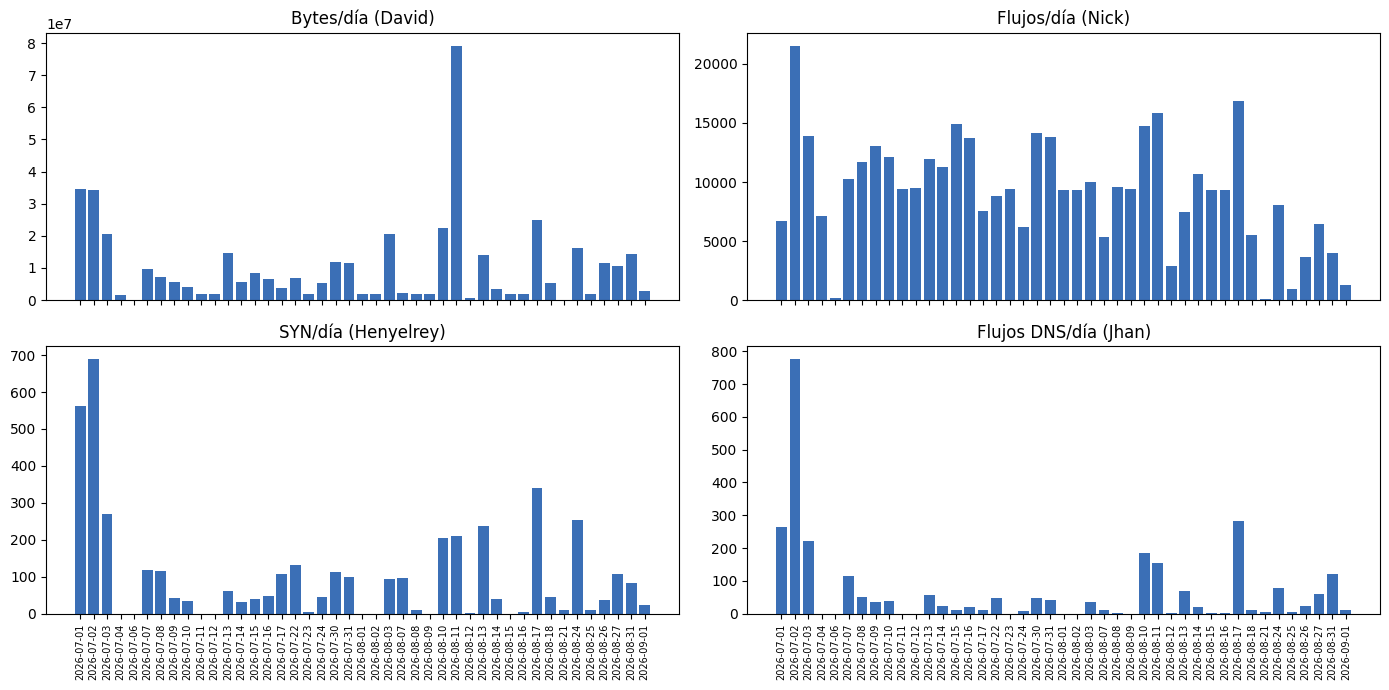

In [7]:
diario = (gold_df.groupBy("fecha").agg(F.sum("flujos").alias("flujos"), F.sum("bytes").alias("bytes"),
                                       F.sum("syn").alias("syn"), F.sum("dns").alias("dns"))
          .orderBy("fecha").toPandas())
fig, ejes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for eje, col, titulo in zip(ejes.flat, ["bytes", "flujos", "syn", "dns"],
                            ["Bytes/día (David)", "Flujos/día (Nick)", "SYN/día (Henyelrey)", "Flujos DNS/día (Jhan)"]):
    eje.bar(diario["fecha"].astype(str), diario[col], color="#3b6fb6")
    eje.set_title(titulo)
    eje.tick_params(axis="x", rotation=90, labelsize=7)
plt.tight_layout()
plt.show()

**Conclusión.** El histórico tiene 43 días con captura entre julio y septiembre,
sin nulos ni negativos en las columnas clave. Los huecos (días sin datos)
corresponden a días en que el equipo de captura estuvo apagado: por eso los
modelos de serie de tiempo solo usan pares de minutos consecutivos. Los
fines de semana tienen un volumen mucho menor que los días de clase.